<a href="https://colab.research.google.com/github/Lupo6789/tesi_scacchi/blob/main/04_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 04: Model Selection e Cross-Validation

In questo notebook viene condotta la fase cruciale di **Model Selection e Validazione** per quantificare l'impatto predittivo del *feature engineering* posizionale (sviluppato nel Notebook 02) sull'esito delle partite di scacchi. L'analisi traccia l'evoluzione delle performance degli algoritmi al progredire del gioco, valutando i dati a diverse soglie di semimosse (N = 10, 20, 30, 40).

Per garantire il massimo rigore accademico e rispondere in modo proattivo a potenziali criticità statistiche intrinseche ai dataset scacchistici, il processo di validazione è stato strutturato sui seguenti pilastri metodologici:

* **Confronto Multi-Algoritmo:** Vengono addestrati e confrontati tre modelli di natura profondamente diversa: un modello lineare interpretabile (*Logistic Regression*) e due modelli non lineari basati su alberi decisionali (*Random Forest* e *LightGBM*).
* **Baseline Dinamica e Calcolo del "Gain":** Per misurare il reale valore aggiunto delle variabili posizionali (vantaggio materiale, mobilità, ecc.), le metriche dei modelli completi vengono confrontate con una *Baseline* addestrata esclusivamente sulla differenza di Elo tra i giocatori (`rating_diff`). Questo permette di isolare il contributo predittivo della scacchiera rispetto alla mera disparità di forza iniziale.
* **Controllo di Robustezza (Anti-Leakage):** Per escludere il rischio di *leakage indiretto* (ovvero che l'algoritmo generalizzi memorizzando lo stile di gioco di utenti molto attivi), la classica `StratifiedKFold` viene affiancata da una `StratifiedGroupKFold` basata sull'ID del giocatore col Bianco, isolando i giocatori tra i set di addestramento e test.
* **Significatività Statistica (Differenze Appaiate):** Il confronto tra i modelli, così come il calcolo del guadagno sulla baseline, non si basa sul delta delle medie finali, ma sulla sottrazione esatta *fold-per-fold* sulle medesime partizioni di dati, permettendo di distinguere un miglioramento strutturale dal semplice rumore stocastico.
* **Analisi dell'Orizzonte Predittivo:** Sulla soglia più avanzata (N=40), l'efficacia del modello viene testata disaggregando i risultati in base alle mosse effettivamente rimanenti alla fine della partita. Questo test verifica se le feature siano in grado di intercettare complessi vantaggi posizionali a lungo termine o se si limitino a prevedere *blunder* (sviste) imminenti.

Le metriche di riferimento per le valutazioni sono il **ROC-AUC** (indicatore principale del potere predittivo e diagnostico), l'**Accuratezza** (per l'impatto percentuale effettivo) e la **Log-Loss** (per misurare la certezza probabilistica dell'algoritmo).

--- NOTEBOOK 04: MODEL SELECTION E CROSS-VALIDATION SUL TRAIN SET ---

Caricamento dataset originale per recupero ID...

Addestramento in Cross-Validation in corso

Valutazione modelli per N=10...
Valutazione modelli per N=20...
Valutazione modelli per N=30...
Valutazione modelli per N=40...

 RISULTATI PRINCIPALI: STANDARD vs GROUP CV
 N             Modello      Accuracy      Log-Loss     AUC (Std)     AUC (Grp) Gain (Fold-Diff)
10 Logistic Regression 0.650 ± 0.007 0.616 ± 0.004 0.715 ± 0.006 0.715 ± 0.013   +0.002 ± 0.002
10       Random Forest 0.650 ± 0.008 0.617 ± 0.005 0.714 ± 0.008 0.711 ± 0.015   +0.001 ± 0.003
10            LightGBM 0.646 ± 0.005 0.621 ± 0.006 0.708 ± 0.007 0.703 ± 0.014   -0.006 ± 0.004
20 Logistic Regression 0.669 ± 0.006 0.600 ± 0.006 0.736 ± 0.008 0.735 ± 0.007   +0.026 ± 0.003
20       Random Forest 0.664 ± 0.009 0.602 ± 0.006 0.733 ± 0.008 0.734 ± 0.004   +0.024 ± 0.003
20            LightGBM 0.658 ± 0.006 0.607 ± 0.008 0.727 ± 0.009 0.725 ± 0.005   +0.01

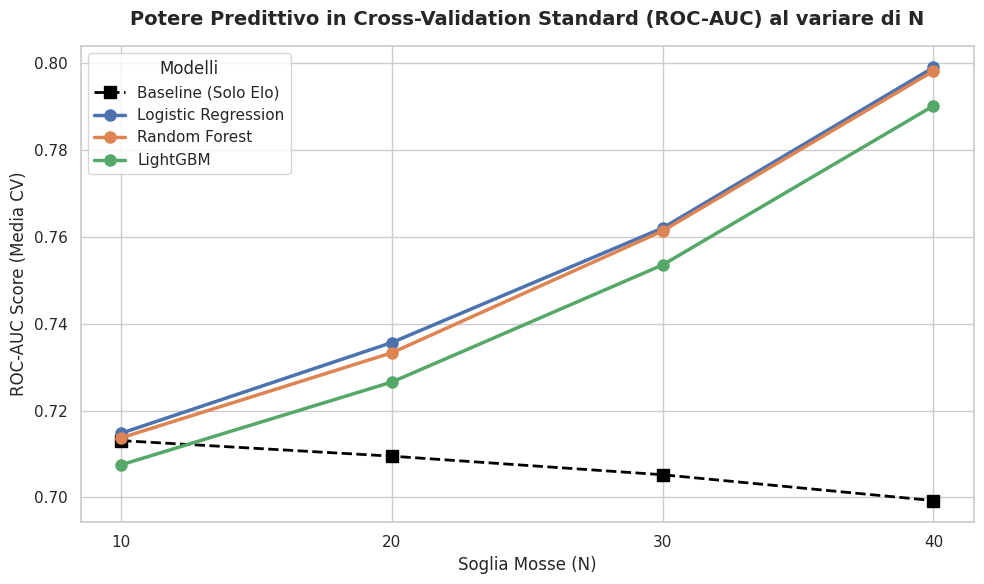


  ANALISI DI PROFONDITA' A N=40 (FASCE DI MOSSE RIMANENTI) ---
        Fascia Rimanenti  N. Partite AUC (Baseline) AUC (LogReg) Gain Assoluto
    1-10 (Breve termine)        2004          0.743        0.877        +0.134
   11-20 (Medio termine)        2075          0.689        0.820        +0.131
Oltre 20 (Lungo termine)        6056          0.688        0.759        +0.071


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
import warnings
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_predict

warnings.filterwarnings('ignore')
print("--- NOTEBOOK 04: MODEL SELECTION E CROSS-VALIDATION SUL TRAIN SET ---\n")

# 1. IMPOSTAZIONI INIZIALI E DEFINIZIONE DEI MODELLI

# Definiamo due tipi di validazione per rispondere al problema del "leakage":
# Standard: divide a caso mantenendo le proporzioni di vittoria (Stratified)
# Group: fa in modo che lo stesso giocatore (white_id) non finisca mai sia in addestramento che in test
cv_standard = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_group = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Inizializziamo i 3 modelli scelti.
# La Regressione Logistica ha bisogno di scalare i dati (StandardScaler) per funzionare bene.
modelli = {
    'Logistic Regression': Pipeline([('sc', StandardScaler()), ('lr', LogisticRegression(max_iter=1000))]),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42, n_jobs=-1),
    'LightGBM': LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1),
}

# Liste per salvare i risultati da stampare poi nelle tabelle
righe_principali = []
righe_confronto = []

# Dizionario per accumulare i dati che ci serviranno per disegnare il grafico finale
risultati_plot = {'N': [10, 20, 30, 40], 'Logistic Regression': [], 'Random Forest': [], 'LightGBM': [], 'Baseline (Solo Elo)': []}

print("Caricamento dataset originale per recupero ID...\n")
# Carichiamo il dataset originale pulito solo per recuperare 'white_id' senza barare
df_cleaned = pd.read_csv('train_cleaned.csv')[['id', 'white_id']]

print("Addestramento in Cross-Validation in corso\n")

# 2. CICLO DI ADDESTRAMENTO PER OGNI SOGLIA N

for N in [10, 20, 30, 40]:
    print(f"Valutazione modelli per N={N}...")

    # Carichiamo le feature calcolate nel Notebook 02 per questa specifica soglia N
    # ('rating_diff' e 'rating_mean' sono già inclusi nei CSV, senza 'white_rating' e 'black_rating')
    df = pd.read_csv(f'train_features_N{N}.csv').dropna()

    # Uniamo il df attuale con df_cleaned per recuperare 'white_id', serve per creare i gruppi
    if 'white_id' in df.columns:
        df = df.drop(columns=['white_id'])
    df = df.merge(df_cleaned, on='id', how='left').dropna(subset=['white_id'])

    # y = target da indovinare, groups = variabile per controllare il leakage indiretto
    y = df['winner']
    groups = df['white_id']

    # ELIMINIAMO GLI ID: per evitare leakage, l'algoritmo non deve mai "vedere" chi sta giocando
    colonne_da_escludere = ['winner', 'id', 'white_id', 'black_id']
    X = df.drop(columns=[c for c in colonne_da_escludere if c in df.columns])

    #CALCOLO DELLA BASELINE (SOLO ELO)
    # Valuto quanto saremmo precisi se guardassimo *solo* la differenza di Elo e ignorassimo la scacchiera
    res_base_std = cross_validate(modelli['Logistic Regression'], df[['rating_diff']], y, cv=cv_standard, scoring='roc_auc')
    auc_base_folds = res_base_std['test_score'] # Salviamo l'array con i voti delle 5 singole fette (fold)

    # Facciao la stessa cosa per la Group CV
    res_base_grp = cross_validate(modelli['Logistic Regression'], df[['rating_diff']], y, groups=groups, cv=cv_group, scoring='roc_auc')
    auc_base_grp_mean = res_base_grp['test_score'].mean()

    # Salvo la media della Baseline per disegnarla dopo nel grafico
    risultati_plot['Baseline (Solo Elo)'].append(auc_base_folds.mean())

    folds_per_modello = {} # Ci servirà per fare la sottrazione "Logistica meno Random Forest" alla fine

    # VALUTAZIONE DEI MODELLI COMPLETI
    for nome, m in modelli.items():
        # A) Standard CV: uso TUTTE le feature (X) e calcolo tutte le metriche
        r_std = cross_validate(m, X, y, cv=cv_standard, scoring=['accuracy', 'roc_auc', 'neg_log_loss'])
        auc_std_folds = r_std['test_roc_auc']#contiene  5 voti auc
        folds_per_modello[nome] = auc_std_folds

        acc_std_mean, acc_std_std = r_std['test_accuracy'].mean(), r_std['test_accuracy'].std()
        loss_std_mean, loss_std_std = -r_std['test_neg_log_loss'].mean(), r_std['test_neg_log_loss'].std()

        # Sottrazione esatta "Fetta per Fetta" (per isolare il rumore statistico)
        gain_folds = auc_std_folds - auc_base_folds #differenza tra AUC della cvstd e cvBaseline
        gain_mean, gain_std = gain_folds.mean(), gain_folds.std()

        # B) Group CV: uso TUTTE le feature ma raggruppo i giocatori per misurare il Leakage
        r_grp = cross_validate(m, X, y, groups=groups, cv=cv_group, scoring='roc_auc')
        auc_grp_mean, auc_grp_std = r_grp['test_score'].mean(), r_grp['test_score'].std()

        # Salvo tutto in una riga della tabella
        righe_principali.append({
            'N': N,
            'Modello': nome,
            'Accuracy': f"{acc_std_mean:.3f} ± {acc_std_std:.3f}",
            'Log-Loss': f"{loss_std_mean:.3f} ± {loss_std_std:.3f}",
            'AUC (Std)': f"{auc_std_folds.mean():.3f} ± {auc_std_folds.std():.3f}", #vengono messi nella tabella direttamente da qua
            'AUC (Grp)': f"{auc_grp_mean:.3f} ± {auc_grp_std:.3f}",
            'Gain (Fold-Diff)': f"{gain_mean:+.3f} ± {gain_std:.3f}"
        })

        # Aggiorno i dati del grafico
        risultati_plot[nome].append(auc_std_folds.mean())

    # -- TEST DI PARITÀ STATISTICA (LogReg vs Random Forest) --
    # Sottraiamo i voti di LogReg e RF fetta per fetta. Se la deviazione standard è più grande della media,
    # significa che non c'è un vero vincitore (Parità statistica).
    diff_lr_rf = folds_per_modello['Logistic Regression'] - folds_per_modello['Random Forest']

    righe_confronto.append({
        'N': N,
        'LR meno RF (Fold-Diff ROC-AUC)': f"{diff_lr_rf.mean():+.3f} ± {diff_lr_rf.std():.3f}"
    })
# 3. STAMPA TABELLE E GRAFICO

print("\n RISULTATI PRINCIPALI: STANDARD vs GROUP CV")
print(pd.DataFrame(righe_principali).to_string(index=False))

print("\nCONFRONTO DIRETTO FOLD-PER-FOLD")
print(pd.DataFrame(righe_confronto).to_string(index=False))

plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Disegna la linea della Baseline (Tratteggiata Nera)
plt.plot(risultati_plot['N'], risultati_plot['Baseline (Solo Elo)'], marker='s', linestyle='--', color='black', linewidth=2, markersize=8, label='Baseline (Solo Elo)')

# Disegna gli altri modelli
for modello in modelli.keys():
    plt.plot(risultati_plot['N'], risultati_plot[modello], marker='o', linewidth=2.5, markersize=8, label=modello)

plt.title("Potere Predittivo in Cross-Validation Standard (ROC-AUC) al variare di N", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Soglia Mosse (N)", fontsize=12)
plt.ylabel("ROC-AUC Score (Media CV)", fontsize=12)
plt.xticks([10, 20, 30, 40])
plt.legend(title="Modelli", fontsize=11, title_fontsize=12)
plt.tight_layout()
plt.show()

# 4. ANALISI DELL'ORIZZONTE PREDITTIVO A N=40 (FASCE DI MOSSE RIMANENTI)
# Serve a dimostrare che il modello funziona bene anche in partite lunghe ed equilibrate,
# e non indovina solo le partite che stanno per finire a causa di errori grossolani.

print("\n  ANALISI DI PROFONDITA' A N=40 (FASCE DI MOSSE RIMANENTI) ---")

#Ricarico solo i dati di N=40
df_40 = pd.read_csv('train_features_N40.csv').dropna()
#Recupero dal dataset originale la colonna 'moves' che contiene l'elenco di tutte le mosse giocate
df_cleaned_moves = pd.read_csv('train_cleaned.csv')[['id', 'moves']]
df_40 = df_40.merge(df_cleaned_moves, on='id', how='left').dropna(subset=['moves'])

# Trasformo la stringa di testo contenente la storia della partita nel NUMERO totale di mosse giocate.

df_40['mosse_totali'] = df_40['moves'].apply(lambda x: len(str(x).split()))

# Sottraggo 40 al totale per scoprire quante mosse mancavano alla fine della partita
df_40['mosse_rimanenti'] = df_40['mosse_totali'] - 40

# Funzione per dividere le partite in 3 gruppi in base a quanto sono durate dopo N=40
def assegna_fascia(rimanenti):
    if rimanenti <= 10: return '1-10 (Breve termine)'
    elif rimanenti <= 20: return '11-20 (Medio termine)'
    else: return 'Oltre 20 (Lungo termine)'

df_40['fascia'] = df_40['mosse_rimanenti'].apply(assegna_fascia)#Assegna alla partita la sua fascia

y_40 = df_40['winner']

#Rimuovo rigorosamente le colonne temporanee (mosse_totali, mosse_rimanenti, fascia)
#per evitare leakage
colonne_escluse = ['winner', 'id', 'white_id', 'black_id', 'moves', 'mosse_totali', 'mosse_rimanenti', 'fascia']
X_40 = df_40.drop(columns=[c for c in colonne_escluse if c in df_40.columns])

modello_orizzonte = Pipeline([('sc', StandardScaler()), ('lr', LogisticRegression(max_iter=1000))])#è necessario standardizzare per non sballare i valori

#cross_val_predict simula una previsione onesta per ogni partita (prevedendola solo quando è nel test fold)
probas_modello = cross_val_predict(modello_orizzonte, X_40, y_40, cv=cv_standard, method='predict_proba')[:, 1] #modello che guarda le varie feature
probas_base = cross_val_predict(modello_orizzonte, df_40[['rating_diff']], y_40, cv=cv_standard, method='predict_proba')[:, 1]#guarda solo la rating diff

risultati_fasce = []

# Calcolo l'AUC (potere predittivo) filtrando le previsioni fascia per fascia
for fascia in ['1-10 (Breve termine)', '11-20 (Medio termine)', 'Oltre 20 (Lungo termine)']: #guarda una fascia per volta
    mask = df_40['fascia'] == fascia # Filtro logico per isolare solo le partite di questa fascia
    y_vero_fascia = y_40[mask] #soluzioni solo per le partite di quella fascia

    auc_m = roc_auc_score(y_vero_fascia, probas_modello[mask])
    auc_b = roc_auc_score(y_vero_fascia, probas_base[mask])

    risultati_fasce.append({
        'Fascia Rimanenti': fascia,
        'N. Partite': mask.sum(),
        'AUC (Baseline)': f"{auc_b:.3f}",
        'AUC (LogReg)': f"{auc_m:.3f}",
        'Gain Assoluto': f"+{(auc_m - auc_b):.3f}"
    })

print(pd.DataFrame(risultati_fasce).to_string(index=False))

#Conclusioni: Validazione e Analisi Predittiva

L'esecuzione del framework di validazione ha restituito risultati chiari e statisticamente significativi, permettendo di trarre conclusioni fondamentali sul comportamento dei modelli e rispondendo puntualmente alle criticità metodologiche sollevate in fase di impostazione.

1. Validazione delle Feature Posizionali e Incremento vs Baseline:
Si osserva un marcato e costante incremento del potere predittivo per tutti gli algoritmi al progredire della partita. Passando dalla fase di apertura (N=10) al mediogioco (N=40), la metrica ROC-AUC generale cresce da circa 0.71 a ridosso dello 0.80, accompagnata da un crollo della Log-Loss, testimoniando una crescente certezza probabilistica nelle previsioni.
Il dato più rilevante emerge analizzando il salto prestazionale rispetto alla baseline (valutata sul solo divario Elo). A N=10 l'apporto delle feature posizionali è nullo poiché la scacchiera è quasi invariata. A N=40, invece, l'estrazione di variabili come vantaggio materiale e mobilità genera per la Regressione Logistica un incremento netto e assoluto di +0.100 sul ROC-AUC, con Random Forest (+0.099) e LightGBM (+0.093) che registrano guadagni quasi speculari. Spostando l'analisi sull'Accuratezza, la Logistica passa dal 63.5% della baseline al 71.9% (+8.4 punti percentuali), un balzo condiviso strettamente anche dagli algoritmi ad albero (rispettivamente 71.8% e 71.2%). Il netto miglioramento registrato in entrambe le metriche da tutti gli algoritmi certifica in modo inequivocabile il successo del feature engineering.

2. Controllo di Robustezza per Giocatore (Anti-Leakage)
Per misurare concretamente il rischio di leakage indiretto legato agli ID degli utenti (es. l'algoritmo che memorizza lo stile di un giocatore molto frequente nel set di addestramento), la validazione standard è stata affiancata da una StratifiedGroupKFold impostata sulla variabile white_id. I risultati in tabella mostrano che le metriche rimangono pressoché invariate: a N=40 la Regressione Logistica ottiene 0.799 in CV standard e 0.799 in Group CV. Questa equivalenza dimostra che il modello generalizza sfruttando solo le dinamiche oggettive della scacchiera, senza essere "influenzato" dalle identità dei giocatori.

3. Significatività Statistica e Rumore
Per valutare l'effettiva robustezza dei guadagni, il confronto tra modelli e baseline non è stato condotto sulle medie globali, ma calcolando la differenza esatta fold-per-fold. A N=10, il leggero incremento della Logistica sulla Baseline (+0.002) è risultato avere una deviazione standard (± 0.002) che lo identifica chiaramente come rumore stocastico. Al contrario, a N=40, il divario di +0.100 ± 0.007 certifica un miglioramento strutturale e costante.
Inoltre, il calcolo appaiato tra i due modelli migliori (LR meno RF) ha restituito a N=40 un differenziale di +0.001 ± 0.003: l'oscillazione attraverso lo zero ci impone di dichiarare una parità statistica formale tra l'approccio lineare e l'approccio ad albero.

4. Origine del Guadagno a N Alto (Analisi Mosse Rimanenti)
Per scongiurare il dubbio che le alte prestazioni a N=40 derivassero unicamente dall'intercettazione di imminenti sviste (blunder) in partite prossime alla conclusione, l'efficacia del modello è stata testata disaggregando i risultati out-of-fold in fasce di mosse rimanenti. Pur registrando fisiologicamente il picco di scarto (+0.134) nelle partite a "breve termine" (1-10 mosse rimanenti), il modello sovraperforma nettamente la baseline di un sostanzioso +0.071 anche nelle oltre 6000 partite destinate a durare a "lungo termine" (oltre 20 mosse). Ciò certifica che le feature posizionali sono in grado di quantificare vantaggi strategici a lungo respiro, conferendo grande solidità al risultato.

5. Considerazioni sulla Natura del Gioco e Variabili (Ipotesi Operative)
Il pareggio statistico tra Regressione Logistica e Random Forest ci permette di formulare due ipotesi metodologiche molto plausibili. In primo luogo, le prestazioni eccellenti del modello lineare suggeriscono che il vantaggio materiale e posizionale mantenga una natura prevalentemente additiva e lineare. In secondo luogo, è ragionevole ipotizzare che l'aver fornito esplicitamente la variabile rating_diff abbia aiutato le performance del Random Forest, fornendo un nodo decisionale già pronto sul divario di forza (un'affermazione che richiederebbe comunque un formale test di ablazione per avere certezza empirica).

6. Nota Metodologica sul Riferimento per il Guadagno
Per il calcolo del guadagno (Gain) è stata utilizzata e tracciata graficamente la Baseline basata solo su rating_diff (Scenario A), mentre i modelli completi includevano anche le variabili contestuali come tempo ed Elo assoluti (Scenario B). Poiché l'analisi esplorativa del Notebook 03 ha dimostrato che tra lo Scenario A e lo Scenario B non sussiste alcuna differenza predittiva di rilievo, adottare lo Scenario A come linea dello zero risulta il riferimento più pulito per isolare e quantificare l'esatto apporto delle nuove feature posizionali.